# Transport in Europe: Motorisation and Emissions

Question 1: What explains how many cars a country has per inhabitant?

Question 2: What explains the transport emissions per capita?

The data come from Eurostat. We use one model for each question.

## 1. Setup

In [ ]:
!pip install eurostat

In [ ]:
import eurostat
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.stats.diagnostic as smd
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson
from scipy import stats

## 2. Configuration

The dataset codes and the filter values. Some Eurostat tables contain more than
one unit, so we have to pick one.

In [ ]:
CARS_CODE = "road_eqs_carhab"       # cars per 1000 inhabitants
GDP_CODE = "sdg_08_10"              # GDP per capita
DENSITY_CODE = "tps00003"           # population density
POP_CODE = "tps00001"               # population
AGE_CODE = "road_eqs_carage"        # cars by age
EMISSION_CODE = "env_air_gge"       # greenhouse gases by sector

GDP_UNIT = "CLV20_EUR_HAB"          # euro per capita, not the growth rate
AGE_UNIT = "NR"                     # number of cars
AGE_10_TO_20 = "Y10-20"             # cars 10 to 20 years old
AGE_ABOVE_20 = "Y_GT20"             # cars older than 20 years
AIRPOL = "GHG"                      # greenhouse gases
SECTOR = "CRF1A3"                   # transport
EMISSION_UNIT = "THS_T"             # thousand tonnes

START_YEAR = 2010

## 3. Loading the data

Eurostat gives one column per year. We need one row per country and year, so we
rebuild the table with two loops. We also keep only the two-letter country
codes, because EU27_2020 and EA19 are groups of countries, not countries.

In [ ]:
class EurostatLoader:

    def __init__(self, start_year):
        self.start_year = start_year

    def load(self, dataset_code):
        return eurostat.get_data_df(dataset_code)

    def to_long(self, raw, value_name):
        year_columns = []
        for column in raw.columns:
            if str(column).isdigit():
                year_columns.append(column)

        countries = list(raw["geo\\TIME_PERIOD"])

        country_list = []
        year_list = []
        value_list = []

        for year in year_columns:
            if int(year) >= self.start_year:
                values = list(raw[year])
                for i in range(len(countries)):
                    if len(countries[i]) == 2:
                        country_list.append(countries[i])
                        year_list.append(int(year))
                        value_list.append(values[i])

        long = pd.DataFrame({"country": country_list,
                             "year": year_list,
                             value_name: value_list})
        return long.dropna()


loader = EurostatLoader(START_YEAR)

In [ ]:
raw_cars = loader.load(CARS_CODE)
raw_gdp = loader.load(GDP_CODE)
raw_density = loader.load(DENSITY_CODE)
raw_pop = loader.load(POP_CODE)
raw_age = loader.load(AGE_CODE)
raw_emission = loader.load(EMISSION_CODE)

print("loaded")

### 3.1 The main variables

We count the rows per country and year. The maximum has to be 1. A higher
number means a filter is missing.

In [ ]:
gdp_data = raw_gdp[raw_gdp["unit"] == GDP_UNIT]

cars = loader.to_long(raw_cars, "cars_per_1000")
gdp = loader.to_long(gdp_data, "gdp_pc")
density = loader.to_long(raw_density, "density")
population = loader.to_long(raw_pop, "population")

panel = cars.merge(gdp, on=["country", "year"])
panel = panel.merge(density, on=["country", "year"])
panel = panel.merge(population, on=["country", "year"])

check = panel.groupby(["country", "year"], as_index=False)["gdp_pc"].count()

print("Rows:", panel.shape[0])
print("Countries:", len(panel["country"].unique()))
print("Rows per country and year, maximum:", check["gdp_pc"].max())
panel.head()

### 3.2 Age of the car fleet

We load the two oldest age classes and the total, then compute the share of
cars older than ten years.

In [ ]:
age_data = raw_age[raw_age["unit"] == AGE_UNIT]

old_10_to_20 = loader.to_long(age_data[age_data["age"] == AGE_10_TO_20], "old_10_to_20")
old_above_20 = loader.to_long(age_data[age_data["age"] == AGE_ABOVE_20], "old_above_20")
all_cars = loader.to_long(age_data[age_data["age"] == "TOTAL"], "total")

fleet = old_10_to_20.merge(old_above_20, on=["country", "year"])
fleet = fleet.merge(all_cars, on=["country", "year"])

fleet["old_cars_share"] = (fleet["old_10_to_20"] + fleet["old_above_20"]) / fleet["total"] * 100

print("Rows:", fleet.shape[0])
fleet.head()

### 3.3 Emissions

We keep the greenhouse gases from transport in thousand tonnes and divide them
by the population. That gives tonnes per inhabitant.

In [ ]:
emission_data = raw_emission[raw_emission["airpol"] == AIRPOL]
emission_data = emission_data[emission_data["src_crf"] == SECTOR]
emission_data = emission_data[emission_data["unit"] == EMISSION_UNIT]

emissions = loader.to_long(emission_data, "emission_total")

print("Rows:", emissions.shape[0])
emissions.head()

In [ ]:
panel = panel.merge(emissions, on=["country", "year"])
panel["emission_pc"] = panel["emission_total"] * 1000 / panel["population"]

panel = panel.merge(fleet, on=["country", "year"])
panel = panel.dropna()

check = panel.groupby(["country", "year"], as_index=False)["gdp_pc"].count()

print("Rows:", panel.shape[0])
print("Countries:", len(panel["country"].unique()))
print("Rows per country and year, maximum:", check["gdp_pc"].max())
panel.head()

## 4. Descriptive statistics

In [ ]:
panel[["cars_per_1000", "gdp_pc", "density", "emission_pc", "old_cars_share"]].describe()

We use only the last year. In a panel the same country would appear many
times, and the observations would not be independent.

In [ ]:
latest_year = panel["year"].max()
data = panel[panel["year"] == latest_year]

print("Year:", latest_year)
print("Countries:", data.shape[0])
data.sort_values("emission_pc", ascending=False).head(5)

## 5. Charts

### 5.1 Emissions over time

The average over all countries. Each country counts the same.

In [ ]:
yearly = panel.groupby("year", as_index=False)["emission_pc"].mean()

fig, ax = plt.subplots()
ax.plot(yearly["year"], yearly["emission_pc"])
ax.set_xlabel("Year")
ax.set_ylabel("Tonnes per inhabitant")
ax.set_title("Transport emissions per capita")
plt.show()

### 5.2 The countries compared

This chart shows why we drop Luxembourg later.

In [ ]:
ranked = data.sort_values("emission_pc", ascending=False)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(ranked["country"], ranked["emission_pc"])
ax.set_xlabel("Country")
ax.set_ylabel("Tonnes per inhabitant")
ax.set_title("Transport emissions per capita")
plt.show()

### 5.3 Cars and emissions

In [ ]:
fig, ax = plt.subplots()
ax.scatter(data["cars_per_1000"], data["emission_pc"])
ax.set_xlabel("Cars per 1000 inhabitants")
ax.set_ylabel("Tonnes per inhabitant")
ax.set_title("Cars and emissions")
plt.show()

### 5.4 Correlations

In [ ]:
corr = data[["cars_per_1000", "gdp_pc", "density", "emission_pc", "old_cars_share"]].corr()

fig, ax = plt.subplots()
sns.heatmap(corr, annot=True, cmap="coolwarm", ax=ax)
ax.set_title("Correlation matrix")
plt.show()

5.5 Age of the car fleet by country

The share of each age class in the car fleet. This is what the variable old_cars_share summarises.


In [ ]:
AGE_CLASSES = ["Y_LT2", "Y2-5", "Y5-10", "Y10-20", "Y_GT20"]

shares = all_cars
for age_class in AGE_CLASSES:
    part = loader.to_long(age_data[age_data["age"] == age_class], age_class)
    shares = shares.merge(part, on=["country", "year"])

shares = shares[shares["year"] == latest_year]

fig, ax = plt.subplots(figsize=(10, 5))

bottom = 0
for age_class in AGE_CLASSES:
    share = shares[age_class] / shares["total"] * 100
    ax.bar(shares["country"], share, bottom=bottom, label=age_class)
    bottom = bottom + share

ax.set_xlabel("Country")
ax.set_ylabel("Share of the fleet in percent")
ax.set_title("Age of the car fleet")
ax.legend()
plt.show()

## 6. The sample

We drop Luxembourg. The country sells fuel to drivers from its neighbours, and
its GDP per capita includes people who work there but live abroad. Both
variables of our model are too high because of this. Chart 5.2 shows the
distance to the next country.

We also build the square of GDP. It goes into model 1 because the relation
gets flatter: at some point a household has enough cars.

In [ ]:
data = data.copy()
data["gdp_pc2"] = data["gdp_pc"] ** 2

no_lu = data[data["country"] != "LU"]

print("Observations:", no_lu.shape[0])

## 7. Model 1: cars

`cars_per_1000 = b0 + b1 gdp_pc + b2 gdp_pc^2 + b3 density + b4 old_cars_share + u`

In [ ]:
x_cars = sm.add_constant(no_lu[["gdp_pc", "gdp_pc2", "density", "old_cars_share"]])
model_cars = sm.OLS(no_lu["cars_per_1000"], x_cars).fit()

print(model_cars.summary())

### 7.1 Turning point

For a quadratic relation the top of the curve is at -b / (2a). Above this
income more money does not bring more cars.

In [ ]:
b = model_cars.params["gdp_pc"]
a = model_cars.params["gdp_pc2"]

print("Turning point at", round(-b / (2 * a), 0), "euro")
print("Highest GDP in the sample:", round(no_lu["gdp_pc"].max(), 0), "euro")

## 8. Model 2: emissions

`emission_pc = b0 + b1 cars_per_1000 + b2 gdp_pc + b3 density + b4 old_cars_share + u`

Here GDP is linear. The flattening in model 1 is about the number of cars, not
about the emissions of one car.

In [ ]:
x_emission = sm.add_constant(no_lu[["cars_per_1000", "gdp_pc", "density", "old_cars_share"]])
model_emission = sm.OLS(no_lu["emission_pc"], x_emission).fit()

print(model_emission.summary())

### 8.1 Cars and emissions with a regression line

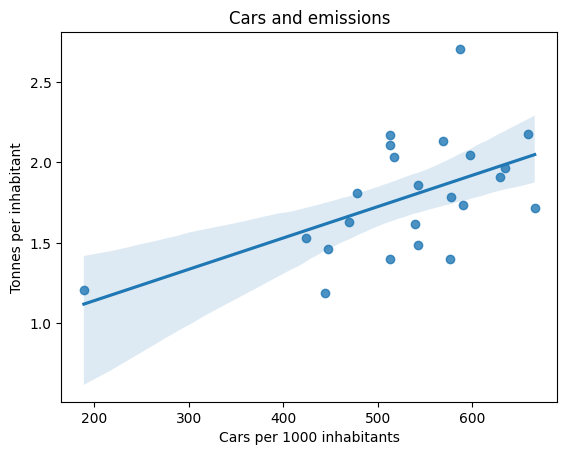

In [42]:
fig, ax = plt.subplots()
sns.regplot(x="cars_per_1000", y="emission_pc", data=no_lu, ax=ax)
ax.set_xlabel("Cars per 1000 inhabitants")
ax.set_ylabel("Tonnes per inhabitant")
ax.set_title("Cars and emissions")
plt.show()

## 9. The two models next to each other

In [43]:
overview = pd.DataFrame()
overview["Model"] = ["1 cars", "2 emissions"]
overview["Dependent variable"] = ["cars_per_1000", "emission_pc"]
overview["N"] = [model_cars.nobs, model_emission.nobs]
overview["R2"] = [model_cars.rsquared, model_emission.rsquared]
overview["adj R2"] = [model_cars.rsquared_adj, model_emission.rsquared_adj]
overview["F p-value"] = [model_cars.f_pvalue, model_emission.f_pvalue]

overview.round(4)

,Model,Dependent variable,N,R2,adj R2,F p-value
0,1 cars,cars_per_1000,23.0,0.5352,0.4319,0.0059
1,2 emissions,emission_pc,23.0,0.6351,0.5540,0.0008


In [44]:
coefficients = pd.DataFrame()
coefficients["Model 1"] = model_cars.params
coefficients["p-value 1"] = model_cars.pvalues
coefficients["Model 2"] = model_emission.params
coefficients["p-value 2"] = model_emission.pvalues

coefficients.round(8)

,Model 1,p-value 1,Model 2,p-value 2
const,-2.352826e+02,0.214460,2.099305,0.000320
gdp_pc,1.828362e-02,0.000388,-0.000014,0.008666
gdp_pc2,-1.600000e-07,0.001484,NaN,NaN
density,-2.677262e-02,0.558297,-0.000291,0.050285
old_cars_share,6.640345e+00,0.003272,-0.021520,0.002864


## 10. The five assumptions

We test both models.

### 10.1 Linearity

The residuals should lie around zero without a pattern. A curve or a funnel
would mean the wrong form.

In [ ]:
fig, ax = plt.subplots()
ax.scatter(model_cars.fittedvalues, model_cars.resid)
ax.set_xlabel("Fitted values")
ax.set_ylabel("Residuals")
ax.set_title("Model 1")
plt.show()

In [ ]:
fig, ax = plt.subplots()
ax.scatter(model_emission.fittedvalues, model_emission.resid)
ax.set_xlabel("Fitted values")
ax.set_ylabel("Residuals")
ax.set_title("Model 2")
plt.show()

### 10.2 Multicollinearity

A VIF above 10 is a problem.

In [ ]:
vif_cars = pd.DataFrame()
vif_cars["Variable"] = x_cars.columns

values = []
for i in range(x_cars.shape[1]):
    values.append(variance_inflation_factor(x_cars.values, i))
vif_cars["VIF"] = values

vif_cars.round(2)

In [ ]:
vif_emission = pd.DataFrame()
vif_emission["Variable"] = x_emission.columns

values = []
for i in range(x_emission.shape[1]):
    values.append(variance_inflation_factor(x_emission.values, i))
vif_emission["VIF"] = values

vif_emission.round(2)

A high VIF for `gdp_pc` and `gdp_pc2` in model 1 is normal. A variable and
its own square are always strongly correlated. This is not a mistake, it only
makes the two single coefficients harder to read.

### 10.3 Homoscedasticity

Breusch-Pagan. A p-value above 0.05 means the variance is constant enough.

In [ ]:
bp_cars = smd.het_breuschpagan(model_cars.resid, x_cars)
bp_emission = smd.het_breuschpagan(model_emission.resid, x_emission)

print("Model 1 p-value:", round(bp_cars[1], 4))
print("Model 2 p-value:", round(bp_emission[1], 4))

### 10.4 Autocorrelation

Durbin-Watson. A value around 2 is fine. Countries have no natural order, so
this test says little here.

In [ ]:
print("Model 1:", round(durbin_watson(model_cars.resid), 3))
print("Model 2:", round(durbin_watson(model_emission.resid), 3))

### 10.5 Normal residuals

The histogram should look like a bell. In the Q-Q plot the points should follow
the line.

In [ ]:
fig, ax = plt.subplots()
sns.histplot(model_cars.resid, kde=True, ax=ax)
ax.set_xlabel("Residual")
ax.set_title("Model 1")
plt.show()

In [ ]:
sm.qqplot(model_cars.resid, line="s")
plt.title("Model 1")
plt.show()

In [ ]:
fig, ax = plt.subplots()
sns.histplot(model_emission.resid, kde=True, ax=ax)
ax.set_xlabel("Residual")
ax.set_title("Model 2")
plt.show()

In [ ]:
sm.qqplot(model_emission.resid, line="s")
plt.title("Model 2")
plt.show()

Shapiro-Wilk. A p-value above 0.05 means the residuals are normal enough.

In [45]:
shapiro_cars = stats.shapiro(model_cars.resid)
shapiro_emission = stats.shapiro(model_emission.resid)

print("Model 1 p-value:", round(shapiro_cars[1], 4))
print("Model 2 p-value:", round(shapiro_emission[1], 4))

Model 1 p-value: 0.3642
Model 2 p-value: 0.9894
